In [55]:
import os 

print(os.getcwd())
os.chdir("../data/")
print(os.getcwd())


print("\nData to be curated:")
os.listdir()

/opt/notebooks/psalms-text-comparison/data
/opt/notebooks/psalms-text-comparison/data

Data to be curated:


['cleaned_psalm_verses.csv',
 'grouped_psalm.csv',
 'psalms_with_bertTopic.csv',
 'psalms_with_data.csv',
 'psalms_with_sentiment.csv',
 'psalms_with_data_2.csv',
 'offical_psalms_data.csv',
 'translationese.csv']

In [56]:
import pandas as pd 

psalms = pd.read_csv("offical_psalms_data.csv")
psalms

,Unnamed: 0,tradition,psalm_num,cleaned_verse,neg,neu,pos,compound,polarity,subjectivity,...,MSTTR.2,MSTTR.3,Cohesive_Markers.2,Cohesive_Markers.3,Word_Count.2,Word_Count.3,text_Psalter,vader_category_Negative,vader_category_Neutral,vader_category_Positive
0,0,Orthodox,1,blessed man walk counsel ungodly stand way sin...,0.015,0.920,0.064,0.7783,0.000000,0.000000,...,0.670000,0.670000,10,10,133,133,0,0,0,1
1,1,Orthodox,2,nation rage people meditate vain thing king ea...,0.120,0.787,0.093,-0.6486,-0.153333,0.400000,...,0.753333,0.753333,12,12,199,199,0,1,0,0
2,2,Orthodox,3,psalm david fled face son absalom olord afflic...,0.089,0.786,0.126,0.8020,0.048889,0.437778,...,0.766667,0.766667,6,6,150,150,0,0,0,1
3,3,Orthodox,4,end psalm ode david heard icalled god righteou...,0.092,0.748,0.159,0.8919,0.178571,0.600000,...,0.813333,0.813333,7,7,165,165,0,0,0,1
4,4,Orthodox,5,end concerning inheritance psalm david give ea...,0.130,0.712,0.157,0.7774,0.075000,0.593750,...,0.700000,0.700000,10,10,248,248,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
296,296,Orthodox,146,lord doth build jerusalem ; shall gather toget...,0.095,0.765,0.141,0.8417,0.157407,0.481481,...,0.720000,0.706667,9,8,184,164,1,0,0,1
297,297,Orthodox,147,"praise lord , jerusalem ; praise thy god , zio...",0.000,0.794,0.206,0.9808,-0.200000,0.650000,...,0.680000,0.670000,6,6,120,126,1,0,0,1
298,298,Orthodox,148,praise ye lord heaven ; praise highest . prais...,0.018,0.749,0.233,0.9946,0.116667,0.316667,...,0.640000,0.610000,20,20,202,207,1,0,0,1
299,299,Orthodox,149,"sing unto lord new song , praise congregation ...",0.017,0.759,0.224,0.9870,0.265455,0.664848,...,0.720000,0.650000,6,7,138,137,1,0,0,1


In [57]:
psalms.columns

Index(['Unnamed: 0', 'tradition', 'psalm_num', 'cleaned_verse', 'neg', 'neu',
       'pos', 'compound', 'polarity', 'subjectivity', 'emotional_score',
       'fk_score', 'gf_score', 'smog_score', 'word_count', 'avg_word_len',
       'syllable_count', 'avg_syllables_per_word', 'polysyllable_count',
       'num_sentences', 'avg_words_sent', 'kathisma_num', 'bertTopic', 'TTR',
       'TTR.1', 'MSTTR', 'MSTTR.1', 'Cohesive_Markers', 'Cohesive_Markers.1',
       'Word_Count', 'Word_Count.1', 'TTR.2', 'TTR.3', 'MSTTR.2', 'MSTTR.3',
       'Cohesive_Markers.2', 'Cohesive_Markers.3', 'Word_Count.2',
       'Word_Count.3', 'text_Psalter', 'vader_category_Negative',
       'vader_category_Neutral', 'vader_category_Positive'],
      dtype='object')

In [58]:
psalms.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 43 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               301 non-null    int64  
 1   tradition                301 non-null    object 
 2   psalm_num                301 non-null    int64  
 3   cleaned_verse            301 non-null    object 
 4   neg                      301 non-null    float64
 5   neu                      301 non-null    float64
 6   pos                      301 non-null    float64
 7   compound                 301 non-null    float64
 8   polarity                 301 non-null    float64
 9   subjectivity             301 non-null    float64
 10  emotional_score          301 non-null    float64
 11  fk_score                 282 non-null    float64
 12  gf_score                 301 non-null    float64
 13  smog_score               301 non-null    float64
 14  word_count               3

Some of the Flesch-Kincaid,`fk_score`,  scores are missing the modeling will break with any missing data. I am going to fill this column with the mean score, to mitigate this issue. 

In [59]:
psalms['fk_score'] = psalms['fk_score'].fillna(psalms['fk_score'].mean())

It seems that there is also missing data in the Kathisma numbering, `kathisma_num`, we are going to see if we can see what number is missing 



In [60]:
psalms.loc[psalms['kathisma_num'].isna(), 'kathisma_num'] = 20

In [61]:
psalms.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 43 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               301 non-null    int64  
 1   tradition                301 non-null    object 
 2   psalm_num                301 non-null    int64  
 3   cleaned_verse            301 non-null    object 
 4   neg                      301 non-null    float64
 5   neu                      301 non-null    float64
 6   pos                      301 non-null    float64
 7   compound                 301 non-null    float64
 8   polarity                 301 non-null    float64
 9   subjectivity             301 non-null    float64
 10  emotional_score          301 non-null    float64
 11  fk_score                 301 non-null    float64
 12  gf_score                 301 non-null    float64
 13  smog_score               301 non-null    float64
 14  word_count               3

There is no longer any missing data, so we can start training some models. 

--- 
# Training a Perceptron 


In [62]:
# from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score

In [63]:
X = psalms[['neg', 'neu', 'pos', 'compound', 'polarity', 'subjectivity', 'emotional_score', 'fk_score',
       'gf_score', 'smog_score', 'word_count', 'avg_word_len', 'syllable_count', 'avg_syllables_per_word', 
       'polysyllable_count', 'num_sentences', 'avg_words_sent', 'kathisma_num', 'bertTopic',
       'vader_category_Negative', 'vader_category_Neutral', 'vader_category_Positive']]

y = psalms['text_Psalter']

In [64]:
#Splitting the dataset to train data and test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [65]:
#Making a perceptron classifier
perceptron = Perceptron(max_iter=100, eta0=0.1, random_state=42)
perceptron.fit(X_train, y_train)

,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",100
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",0.1
,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [66]:
#Making prediction on test data
y_pred = perceptron.predict(X_test)
#Finding accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy}')

Accuracy: 0.45901639344262296


In [67]:
from sklearn.metrics import classification_report
# Generate a classification report
class_report = classification_report(y_test, y_pred)
print("Classification Report:\n", class_report)

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00        31
           1       0.47      0.93      0.63        30

    accuracy                           0.46        61
   macro avg       0.24      0.47      0.31        61
weighted avg       0.23      0.46      0.31        61



In [68]:
import numpy as np
from sklearn.metrics import confusion_matrix

print("Predicted classes:", np.unique(y_pred, return_counts=True))
print("Actual classes:", np.unique(y_test, return_counts=True))
print(confusion_matrix(y_test, y_pred))

Predicted classes: (array([0, 1]), array([ 2, 59]))
Actual classes: (array([0, 1]), array([31, 30]))
[[ 0 31]
 [ 2 28]]


In [69]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import classification_report

model = make_pipeline(
    StandardScaler(),
    Perceptron(max_iter=2000, tol=1e-4, random_state=42)
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.75      0.58      0.65        31
           1       0.65      0.80      0.72        30

    accuracy                           0.69        61
   macro avg       0.70      0.69      0.69        61
weighted avg       0.70      0.69      0.68        61



In [113]:
psalms.columns

Index(['Unnamed: 0', 'tradition', 'psalm_num', 'cleaned_verse', 'neg', 'neu',
       'pos', 'compound', 'polarity', 'subjectivity', 'emotional_score',
       'fk_score', 'gf_score', 'smog_score', 'word_count', 'avg_word_len',
       'syllable_count', 'avg_syllables_per_word', 'polysyllable_count',
       'num_sentences', 'avg_words_sent', 'kathisma_num', 'bertTopic', 'TTR',
       'TTR.1', 'MSTTR', 'MSTTR.1', 'Cohesive_Markers', 'Cohesive_Markers.1',
       'Word_Count', 'Word_Count.1', 'TTR.2', 'TTR.3', 'MSTTR.2', 'MSTTR.3',
       'Cohesive_Markers.2', 'Cohesive_Markers.3', 'Word_Count.2',
       'Word_Count.3', 'text_Psalter', 'vader_category_Negative',
       'vader_category_Neutral', 'vader_category_Positive'],
      dtype='object')

In [114]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import classification_report, confusion_matrix

X = psalms[[
    'neg', 'neu', 'pos', 'compound', 'polarity', 'subjectivity',
    'emotional_score', 'fk_score', 'gf_score', 'smog_score',
    'word_count', 'avg_word_len', 'syllable_count',
    'avg_syllables_per_word', 'polysyllable_count',
    'num_sentences', 'avg_words_sent', 'kathisma_num',
    'bertTopic', 'vader_category_Negative',
    'vader_category_Neutral', 'vader_category_Positive',
    'TTR', 'MSTTR', 'Cohesive_Markers'
]]

y = psalms['text_Psalter']

# Split the data while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Impute missing values, scale features, and train
model = make_pipeline(
    SimpleImputer(strategy='mean'),
    StandardScaler(),
    Perceptron(max_iter=5000, tol=1e-4, random_state=42)
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Predicted class counts:")
print(y_pred.astype(str))
print(np.unique(y_pred, return_counts=True))

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.58      0.62        31
           1       0.62      0.70      0.66        30

    accuracy                           0.64        61
   macro avg       0.64      0.64      0.64        61
weighted avg       0.64      0.64      0.64        61

Confusion Matrix:
[[18 13]
 [ 9 21]]
Predicted class counts:
['1' '0' '0' '0' '0' '0' '1' '0' '0' '0' '1' '1' '1' '1' '1' '1' '1' '1'
 '1' '1' '0' '1' '0' '0' '1' '1' '1' '1' '0' '1' '0' '1' '1' '0' '0' '0'
 '1' '0' '1' '1' '1' '1' '1' '1' '0' '1' '0' '1' '1' '0' '1' '0' '0' '0'
 '0' '0' '1' '1' '1' '0' '0']
(array([0, 1]), array([27, 34]))


In [71]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

log_model = make_pipeline(
    SimpleImputer(strategy='mean'),
    StandardScaler(),
    LogisticRegression(max_iter=5000, random_state=42)
)

log_model.fit(X_train, y_train)
log_pred = log_model.predict(X_test)

print(classification_report(y_test, log_pred, zero_division=0))
print(confusion_matrix(y_test, log_pred))

              precision    recall  f1-score   support

           0       0.73      0.61      0.67        31
           1       0.66      0.77      0.71        30

    accuracy                           0.69        61
   macro avg       0.69      0.69      0.69        61
weighted avg       0.69      0.69      0.69        61

[[19 12]
 [ 7 23]]


--- 
# Being more Selective with Features

Myabe using all possible data is not the best approach for modeling. lets look at the best correlations to use. We are going to use the `Perceptron Model` as a base line for now for comparisons. This was the best model over all. 

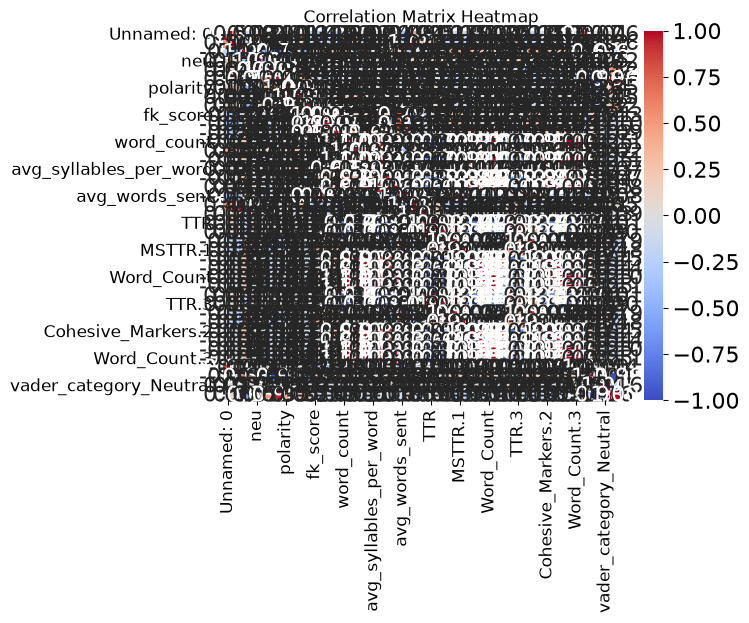

In [72]:
import seaborn as sns 
import matplotlib.pyplot as plt

corr = psalms.corr(numeric_only=True)#['berTopic']

sns.heatmap(
    corr, 
    annot=True,          # Show the correlation coefficients inside the blocks
    cmap='coolwarm',     # Red for positive correlation, blue for negative correlation
    fmt=".2f",           # Round the values to 2 decimal places
    vmin=-1, vmax=1     # Fix the colorbar limits from -1 to 1
)


# Force the title and axis tick labels to font size 12
plt.title('Correlation Matrix Heatmap', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.show()

In [73]:
correlations = corr['text_Psalter'].sort_values(key=abs, ascending=False)

correlations = pd.DataFrame(correlations)
correlations = correlations[2:]
correlations

,text_Psalter
gf_score,-0.339740
avg_words_sent,-0.323501
avg_word_len,0.298793
fk_score,-0.256439
smog_score,-0.211761
bertTopic,-0.085647
subjectivity,0.061269
compound,0.052096
neg,-0.048042
num_sentences,0.043442


We are going to refer to `correlations` to pull the **Top N** features for each trial. 

In [74]:
# The predictor Y is never going to change
y = psalms['text_Psalter']

In [75]:
def perceptron_trial(n=2):

    features = correlations[:n].index.tolist()
    X = psalms[features]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    perceptron = Perceptron(max_iter=100, eta0=0.1, random_state=42)
    perceptron.fit(X_train, y_train)

    y_pred = perceptron.predict(X_test)

    class_report = classification_report(
        y_test, y_pred, output_dict=True, zero_division=0
    )

    # Extract accuracy
    accuracy = class_report.pop("accuracy")

    # Convert remaining metrics into a DataFrame
    report_df = pd.DataFrame(class_report).T

    # Add accuracy as a column
    report_df["accuracy"] = accuracy
    report_df["features_used"] = str(features)
    report_df["n_features"] = n

    return report_df


result_df = perceptron_trial(n=2)
display(result_df)

,precision,recall,f1-score,support,accuracy,features_used,n_features
0,0.000000,0.000000,0.000000,31.0,0.491803,"['gf_score', 'avg_words_sent']",2
1,0.491803,1.000000,0.659341,30.0,0.491803,"['gf_score', 'avg_words_sent']",2
macro avg,0.245902,0.500000,0.329670,61.0,0.491803,"['gf_score', 'avg_words_sent']",2
weighted avg,0.241870,0.491803,0.324266,61.0,0.491803,"['gf_score', 'avg_words_sent']",2


## Classification Report Definitions

### Classes

- **Class 0 (Bible):** Represents Psalms from the Bible text tradition, where `text_Psalter = 0`.
- **Class 1 (Psalter):** Represents Psalms from the Psalter text tradition, where `text_Psalter = 1`.

### Evaluation Metrics

- **Precision:** The proportion of predictions for a class that were correct. For example, class 1 precision measures how many Psalter predictions were actually Psalter texts.

- **Recall:** The proportion of actual instances of a class that the model correctly identified. For example, class 1 recall measures how many actual Psalter texts the model correctly classified.

- **F1-score:** The harmonic mean of precision and recall. It balances both metrics, providing a single measure of classification performance.

- **Support:** The number of actual instances of each class in the evaluation dataset.

### Aggregate Metrics

- **Accuracy:** The proportion of all predictions that the model classified correctly.

- **Macro Average:** The unweighted average of a metric across all classes. Each class contributes equally, regardless of how many examples it contains.

- **Weighted Average:** The average of a metric across all classes, weighted by each class's support. Classes with more examples contribute more to the result.


In [76]:
len(correlations)

39

In [77]:
results = []

for n in range(1, len(correlations)+1):
    report_df = perceptron_trial(n=n)
    report_df["class"] = report_df.index
    results.append(report_df.reset_index(drop=True))

results_df = pd.concat(results, ignore_index=True)

n_feature_results = results_df.copy()

display(results_df)

,precision,recall,f1-score,support,accuracy,features_used,n_features,class
0,0.000000,0.000000,0.000000,31.0,0.491803,['gf_score'],1,0
1,0.491803,1.000000,0.659341,30.0,0.491803,['gf_score'],1,1
2,0.245902,0.500000,0.329670,61.0,0.491803,['gf_score'],1,macro avg
3,0.241870,0.491803,0.324266,61.0,0.491803,['gf_score'],1,weighted avg
4,0.000000,0.000000,0.000000,31.0,0.491803,"['gf_score', 'avg_words_sent']",2,0
...,...,...,...,...,...,...,...,...
151,0.228943,0.442623,0.301788,61.0,0.442623,"['gf_score', 'avg_words_sent', 'avg_word_len',...",38,weighted avg
152,0.000000,0.000000,0.000000,31.0,0.442623,"['gf_score', 'avg_words_sent', 'avg_word_len',...",39,0
153,0.465517,0.900000,0.613636,30.0,0.442623,"['gf_score', 'avg_words_sent', 'avg_word_len',...",39,1
154,0.232759,0.450000,0.306818,61.0,0.442623,"['gf_score', 'avg_words_sent', 'avg_word_len',...",39,macro avg


### Graphing the results to understand 

- Using `macro avg` as a baseline of the model's overall preformance
- **X** = Using `n_features` to to track the best n-top-features that makes the model the best.
- **Y** = Using `f1-score` as it represents both `precision` and `recall` well. 

In [78]:
# filtering for only the 'macro avg' rows
macro_avgs = results_df[results_df['class'] == "macro avg"]

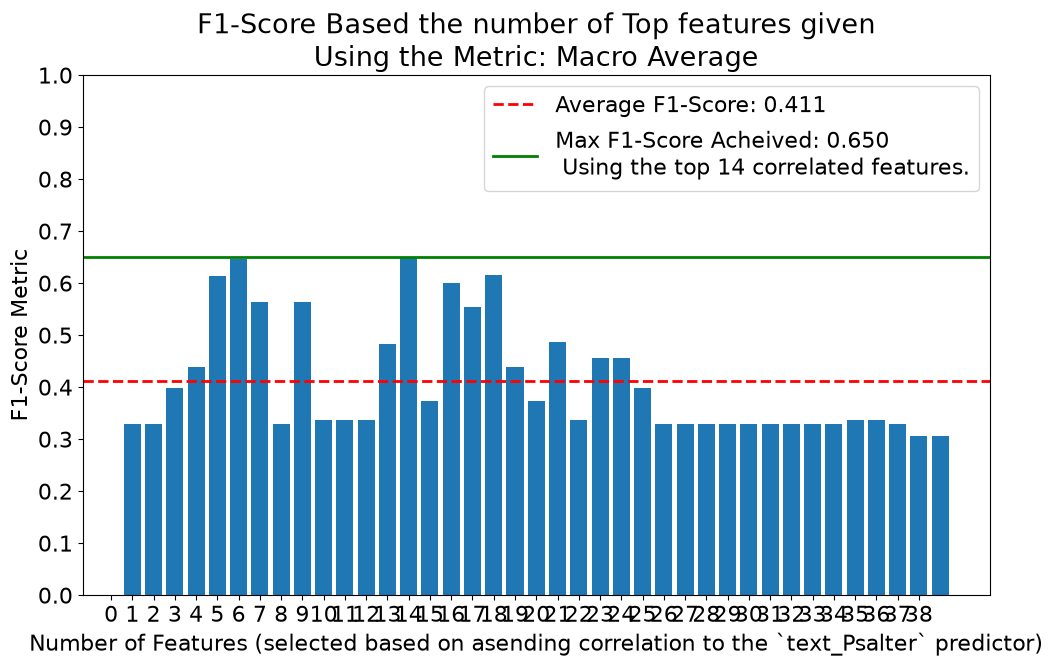

In [79]:
def plot_metric(data, metric):
    x = data['n_features']
    y = data['f1-score']

    # Create bar chart
    plt.figure(figsize=(10, 6))
    plt.bar(x, y)

       
    # Calculate average F1-score
    avg_f1 = y.mean()
    
    # Calculate max F1-score
    max_f1 = y.max()

    # Get the row with the maximum F1-score
    best_row = data.loc[y.idxmax()]

    # Get the number of features used
    best_n_features = best_row['n_features']
    
    # Add red dashed average line
    plt.axhline(
        y=avg_f1,
        color='red',
        linestyle='--',
        linewidth=2,
        label=f'Average F1-Score: {avg_f1:.3f}'
    )
    
    # Add green solid max line
    plt.axhline(
        y=max_f1,
        color='green',
        linestyle='-',
        linewidth=2,
        label=f'Max F1-Score Acheived: {max_f1:.3f} \n Using the top {best_n_features} correlated features.'
    )
    
    plt.xticks(np.arange(0, len(correlations)), ha="center")
    plt.tight_layout()

    plt.ylim(0, 1.0)
    plt.yticks(np.arange(0, 1.1, 0.1))  # Step = 0.1
    
    # Labels and title
    plt.xlabel("Number of Features (selected based on asending correlation to the `text_Psalter` predictor)")
    plt.ylabel("F1-Score Metric")
    plt.title("F1-Score Based the number of Top features given" + f"\nUsing the Metric: {metric}" +
                 "")


    # Display chart
    plt.legend()
    plt.show()
    
plot_metric(macro_avgs, "Macro Average")



## Old Graph: 
![old_psalter_class](images/bible_class_old.png)

---

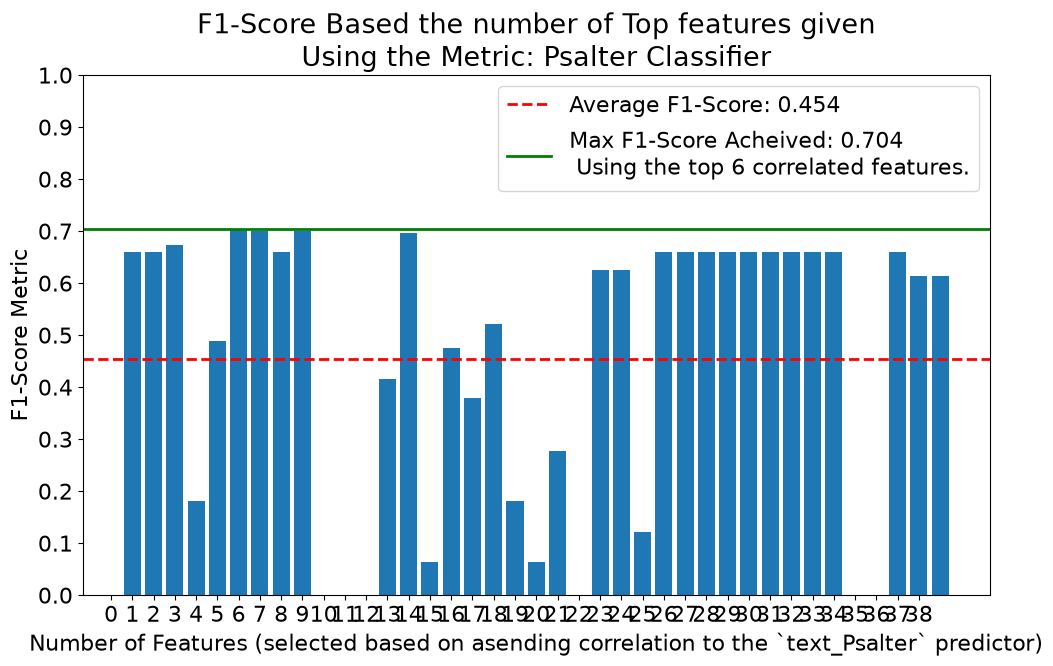

In [80]:
# filtering for only the 'macro avg' rows
psalter_class = results_df[results_df['class'] == "1"] # Psalter classifier

plot_metric(psalter_class, "Psalter Classifier")



## Old Graph: 
![old_psalter_class](images/psalter_class_old.png)

---

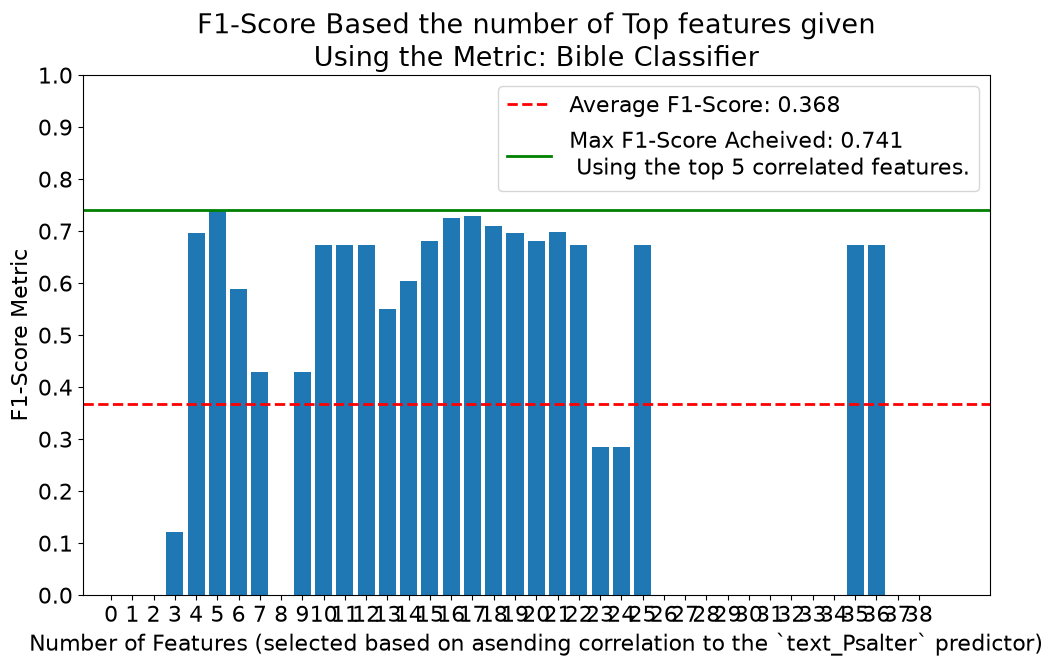

In [81]:
# filtering for only the 'macro avg' rows
bible_class = results_df[results_df['class'] == "0"] # Bible classifier

plot_metric(bible_class, "Bible Classifier")



## Old Graph: 
![old_psalter_class](images/bible_class_old.png)

---

---
## Investigating the Top 5 Correlated Features

It seems a though the top 5 correlated features to `text_psalter`. I can look further into these and determine if there is fine tuning that can be done to improve the model. 

In [82]:
target_features = correlations[:5].index.tolist() # the top 5 correlated features
predictor = ['text_Psalter'] # the column we are trying to classify from 

target_df = pd.concat([psalms[predictor], psalms[target_features]], axis=1)

In [83]:
import itertools 

# Your starting point
target_features = correlations[:5].index.tolist() 

feature_combinations = [
    list(combo) # or np.array(combo) if your downstream pipeline strictly requires NumPy arrays
    for r in range(1, len(target_features) + 1)
    for combo in itertools.combinations(target_features, r)
]

print(f'Number of Combinations: {len(feature_combinations)}')

feature_combinations

Number of Combinations: 31


[['gf_score'],
 ['avg_words_sent'],
 ['avg_word_len'],
 ['fk_score'],
 ['smog_score'],
 ['gf_score', 'avg_words_sent'],
 ['gf_score', 'avg_word_len'],
 ['gf_score', 'fk_score'],
 ['gf_score', 'smog_score'],
 ['avg_words_sent', 'avg_word_len'],
 ['avg_words_sent', 'fk_score'],
 ['avg_words_sent', 'smog_score'],
 ['avg_word_len', 'fk_score'],
 ['avg_word_len', 'smog_score'],
 ['fk_score', 'smog_score'],
 ['gf_score', 'avg_words_sent', 'avg_word_len'],
 ['gf_score', 'avg_words_sent', 'fk_score'],
 ['gf_score', 'avg_words_sent', 'smog_score'],
 ['gf_score', 'avg_word_len', 'fk_score'],
 ['gf_score', 'avg_word_len', 'smog_score'],
 ['gf_score', 'fk_score', 'smog_score'],
 ['avg_words_sent', 'avg_word_len', 'fk_score'],
 ['avg_words_sent', 'avg_word_len', 'smog_score'],
 ['avg_words_sent', 'fk_score', 'smog_score'],
 ['avg_word_len', 'fk_score', 'smog_score'],
 ['gf_score', 'avg_words_sent', 'avg_word_len', 'fk_score'],
 ['gf_score', 'avg_words_sent', 'avg_word_len', 'smog_score'],
 ['gf_sco

In [84]:
def perceptron_trial(features):

    X = psalms[features]
    n = len(features) # documenting the number of features used. 
    
    y = psalms['text_Psalter']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    perceptron = Perceptron(max_iter=100, eta0=0.1, random_state=42)
    perceptron.fit(X_train, y_train)

    # Make predictions
    y_pred = perceptron.predict(X_test)

    # Generate classification report as a dictionary
    class_report = classification_report(
        y_test, y_pred, output_dict=True, zero_division=0
    )

    
    # Extract accuracy
    accuracy = class_report.pop("accuracy")

    # Convert remaining metrics into a DataFrame
    report_df = pd.DataFrame(class_report).T

    # Add accuracy as a column
    report_df["accuracy"] = accuracy
    report_df["features_used"] = str(features)
    report_df["n_features"] = n

    return report_df



There are **31** combinations being ran through the preceptron. Each Trial appending 5 rows of data to the dataframe. We should end up with: 

$$
31\ features\  * 4\ new\ rows = \mathbf{124\ total\_rows}
$$

In [85]:
new_results = []

for feature_set in feature_combinations: 
    new_data = perceptron_trial(feature_set)
    new_data["class"] = new_data.index
    new_results.append(new_data.reset_index(drop=True))

results_df = pd.concat(new_results, ignore_index=True)

# n_feature_results = results_df.copy()

display(results_df)
#perceptron_trial()

,precision,recall,f1-score,support,accuracy,features_used,n_features,class
0,0.000000,0.000000,0.000000,31.0,0.491803,['gf_score'],1,0
1,0.491803,1.000000,0.659341,30.0,0.491803,['gf_score'],1,1
2,0.245902,0.500000,0.329670,61.0,0.491803,['gf_score'],1,macro avg
3,0.241870,0.491803,0.324266,61.0,0.491803,['gf_score'],1,weighted avg
4,0.000000,0.000000,0.000000,31.0,0.491803,['avg_words_sent'],1,0
...,...,...,...,...,...,...,...,...
119,0.762578,0.540984,0.425002,61.0,0.540984,"['avg_words_sent', 'avg_word_len', 'fk_score',...",4,weighted avg
120,0.600000,0.967742,0.740741,31.0,0.655738,"['gf_score', 'avg_words_sent', 'avg_word_len',...",5,0
121,0.909091,0.333333,0.487805,30.0,0.655738,"['gf_score', 'avg_words_sent', 'avg_word_len',...",5,1
122,0.754545,0.650538,0.614273,61.0,0.655738,"['gf_score', 'avg_words_sent', 'avg_word_len',...",5,macro avg


## The head of the Old `results_df` above: 

|   | precision | recall   | f1-score | support   | accuracy | features_used    | n_features | class        |
|---|-----------|----------|----------|-----------|----------|------------------|------------|--------------|
| 0 | 0.000000  | 0.000000 | 0.000000 | 31.000000 | 0.475410 | ['subjectivity'] | 1          | 0            |
| 1 | 0.483333  | 0.966667 | 0.644444 | 30.000000 | 0.475410 | ['subjectivity'] | 1          | 1            |
| 3 | 0.241667  | 0.483333 | 0.322222 | 61.000000 | 0.475410 | ['subjectivity'] | 1          | macro avg    |
| 4 | 0.237705  | 0.475410 | 0.316940 | 61.000000 | 0.475410 | ['subjectivity'] | 1          | weighted avg |

### Updating the Graping to adjsut to showing at most 5 features

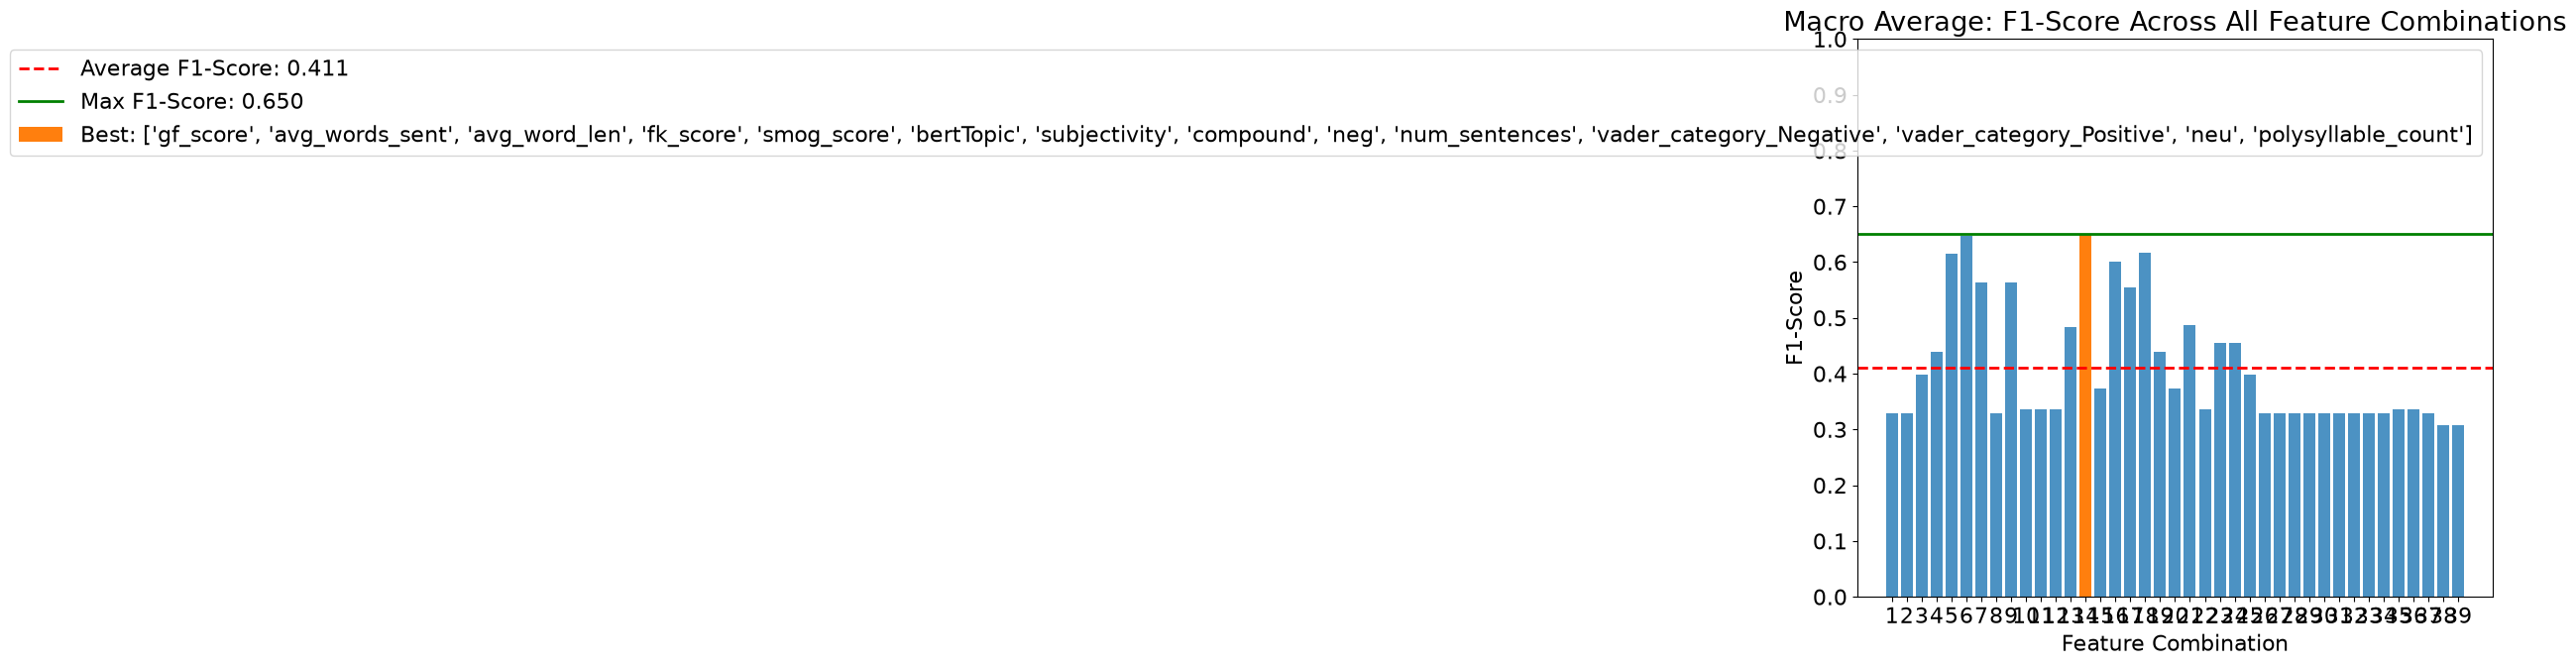

In [86]:
def plot_metric(data, metric):

    data = data.copy().reset_index(drop=True)

    x = np.arange(len(data))
    y = data['f1-score']

    # Calculate average and maximum
    avg_f1 = y.mean()
    max_f1 = y.max()

    best_index = y.idxmax()
    best_row = data.loc[best_index]

    # Create bar chart
    plt.figure(figsize=(18, 7))

    plt.bar(x, y, alpha=0.8)

    # Average line
    plt.axhline(
        avg_f1,
        color='red',
        linestyle='--',
        linewidth=2,
        label=f'Average F1-Score: {avg_f1:.3f}'
    )

    # Maximum line
    plt.axhline(
        max_f1,
        color='green',
        linestyle='-',
        linewidth=2,
        label=f'Max F1-Score: {max_f1:.3f}'
    )

    # Highlight best combination
    plt.bar(
        best_index,
        max_f1,
        label=f'Best: {best_row["features_used"]}',
        alpha=1
    )

    # Axis formatting
    plt.xticks(x, [str(i + 1) for i in x])
    plt.ylim(0, 1.0)
    plt.yticks(np.arange(0, 1.1, 0.1))

    plt.xlabel('Feature Combination')
    plt.ylabel('F1-Score')
    plt.title(f'{metric}: F1-Score Across All Feature Combinations')

    plt.legend()
    plt.tight_layout()
    plt.show()


plot_metric(macro_avgs, "Macro Average")

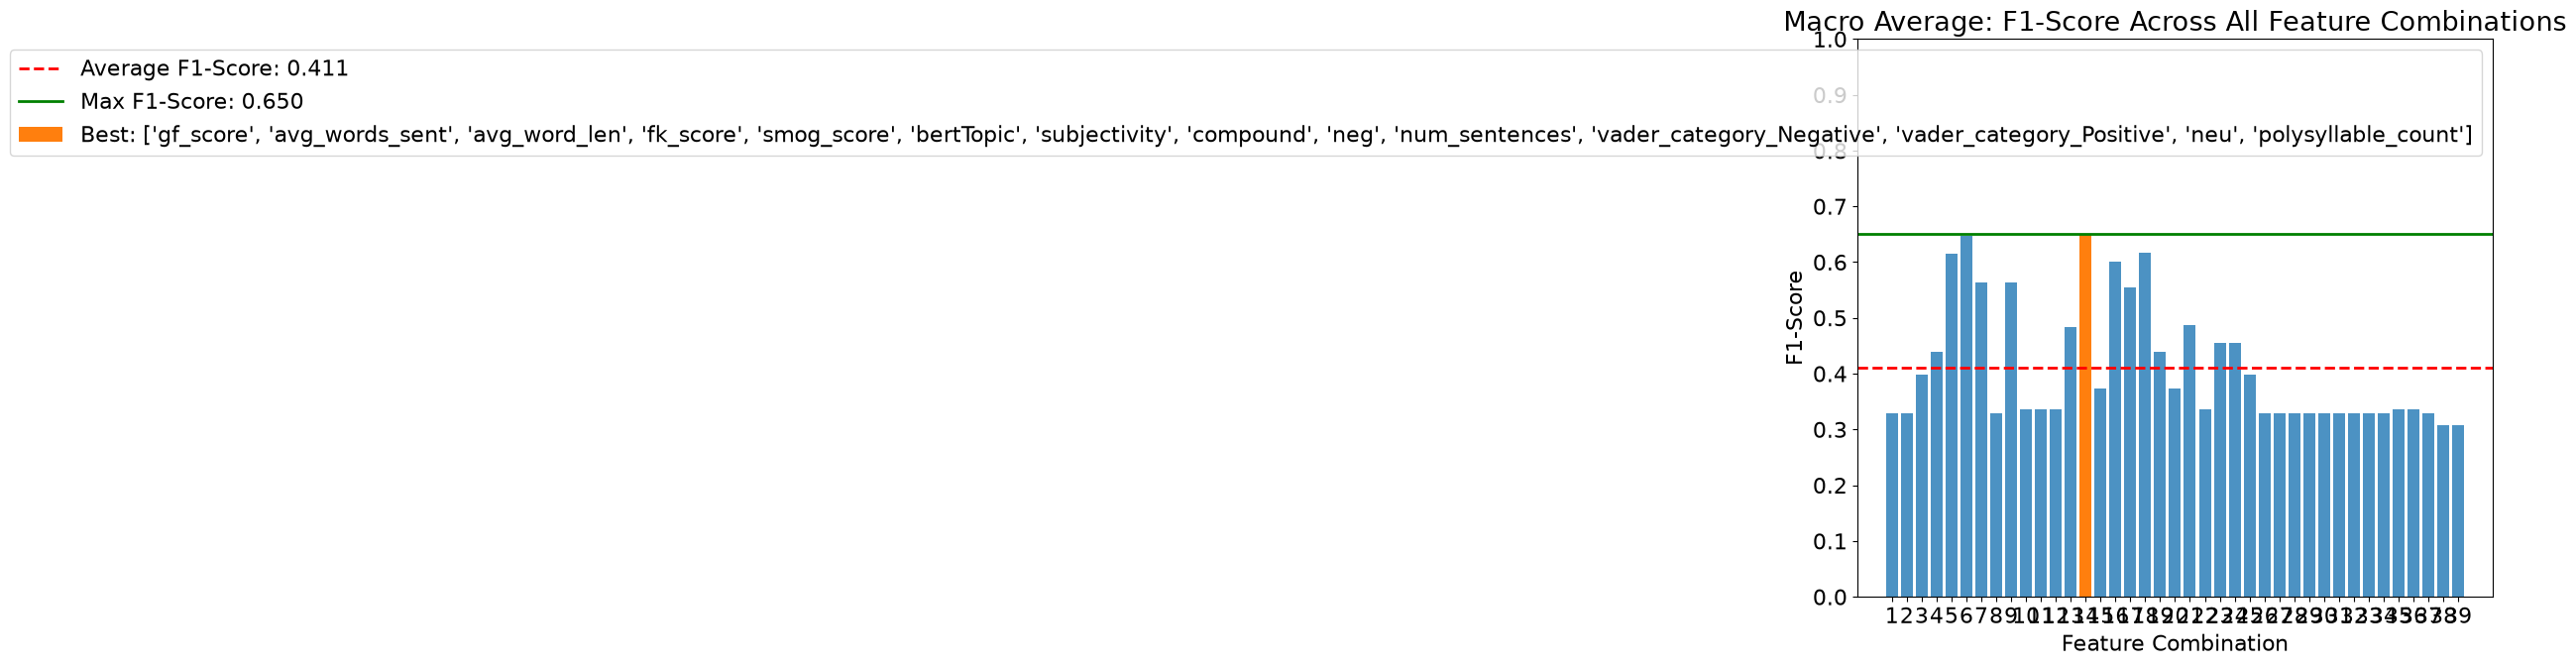

In [87]:
plot_metric(macro_avgs, "Macro Average")

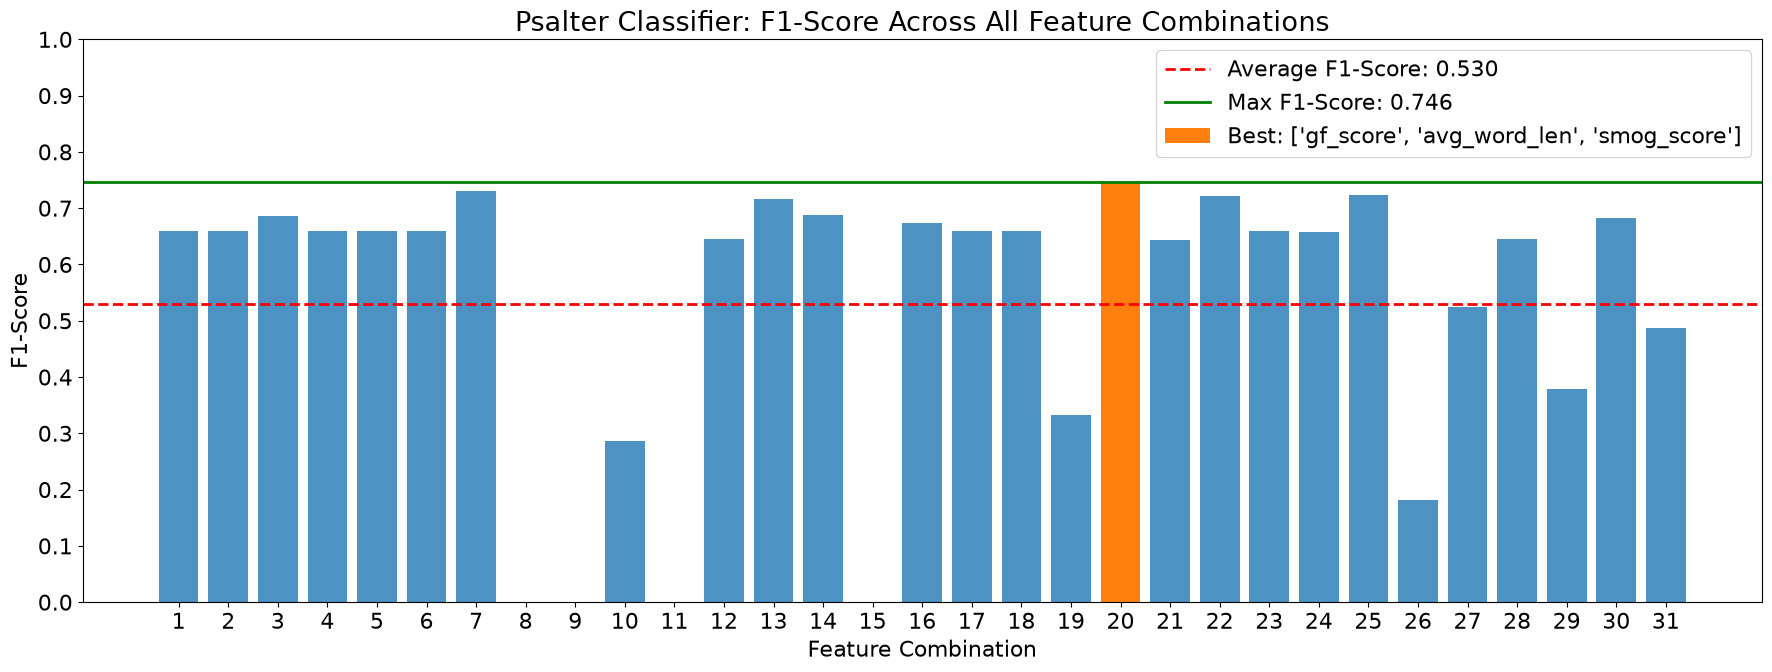

In [88]:
# filtering for only the 'macro avg' rows
psalter_class = results_df[results_df['class'] == "1"] # Psalter classifier

plot_metric(psalter_class, "Psalter Classifier")

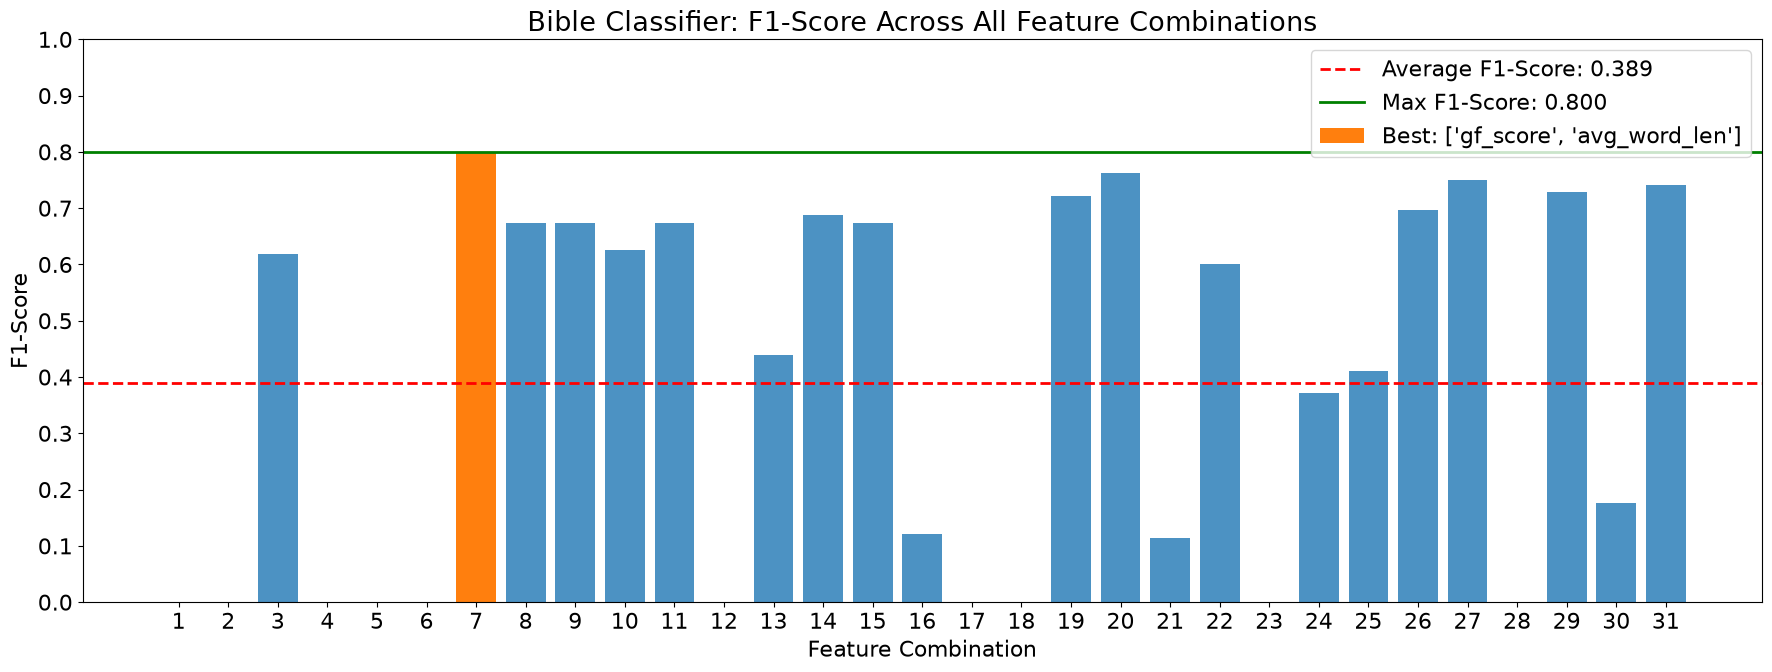

In [89]:
# filtering for only the 'macro avg' rows
bible_class = results_df[results_df['class'] == "0"] # Psalter classifier

plot_metric(bible_class, "Bible Classifier")

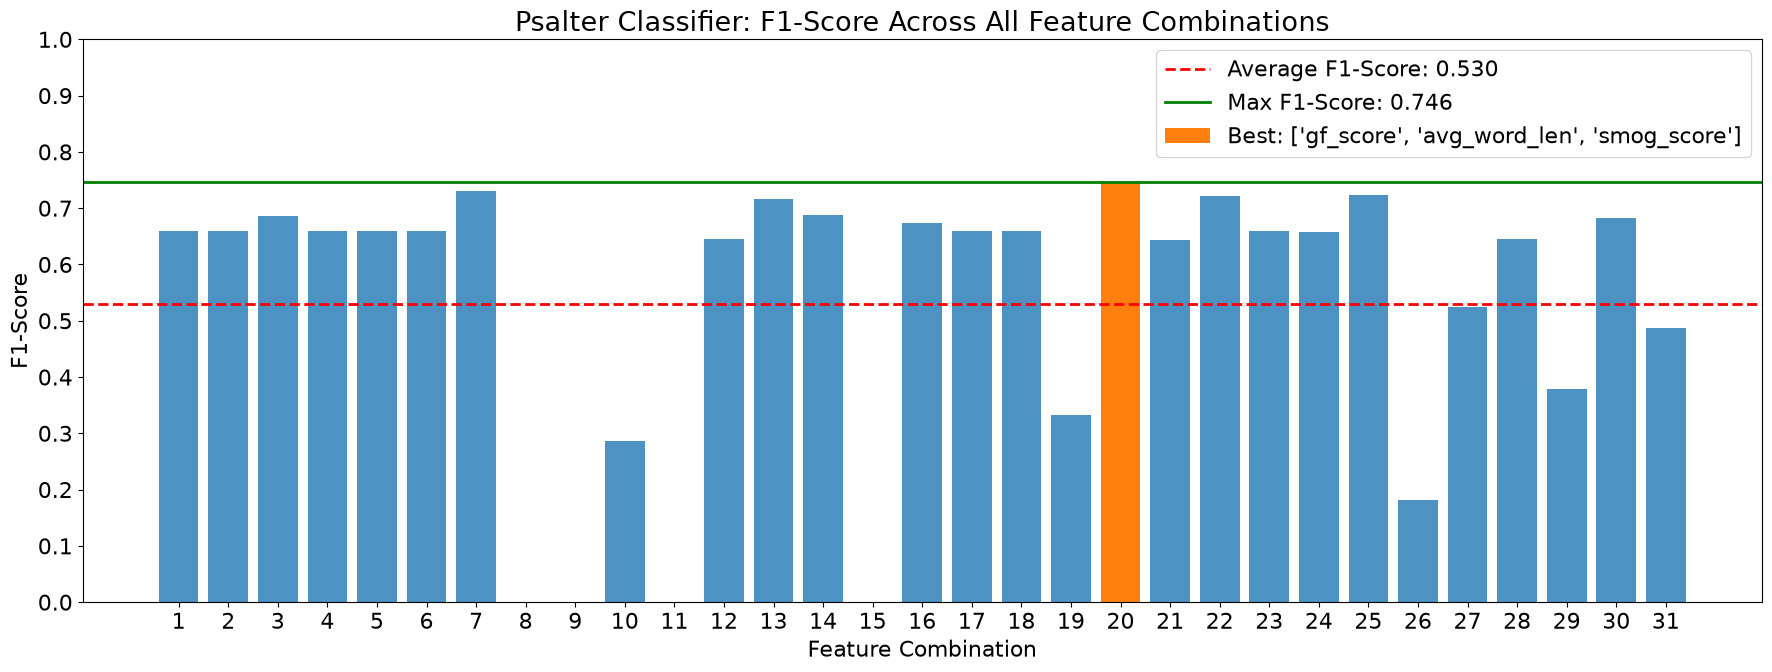

In [90]:
# filtering for only the 'macro avg' rows
psalter_class = results_df[results_df['class'] == "1"] # Psalter classifier

plot_metric(psalter_class, "Psalter Classifier")

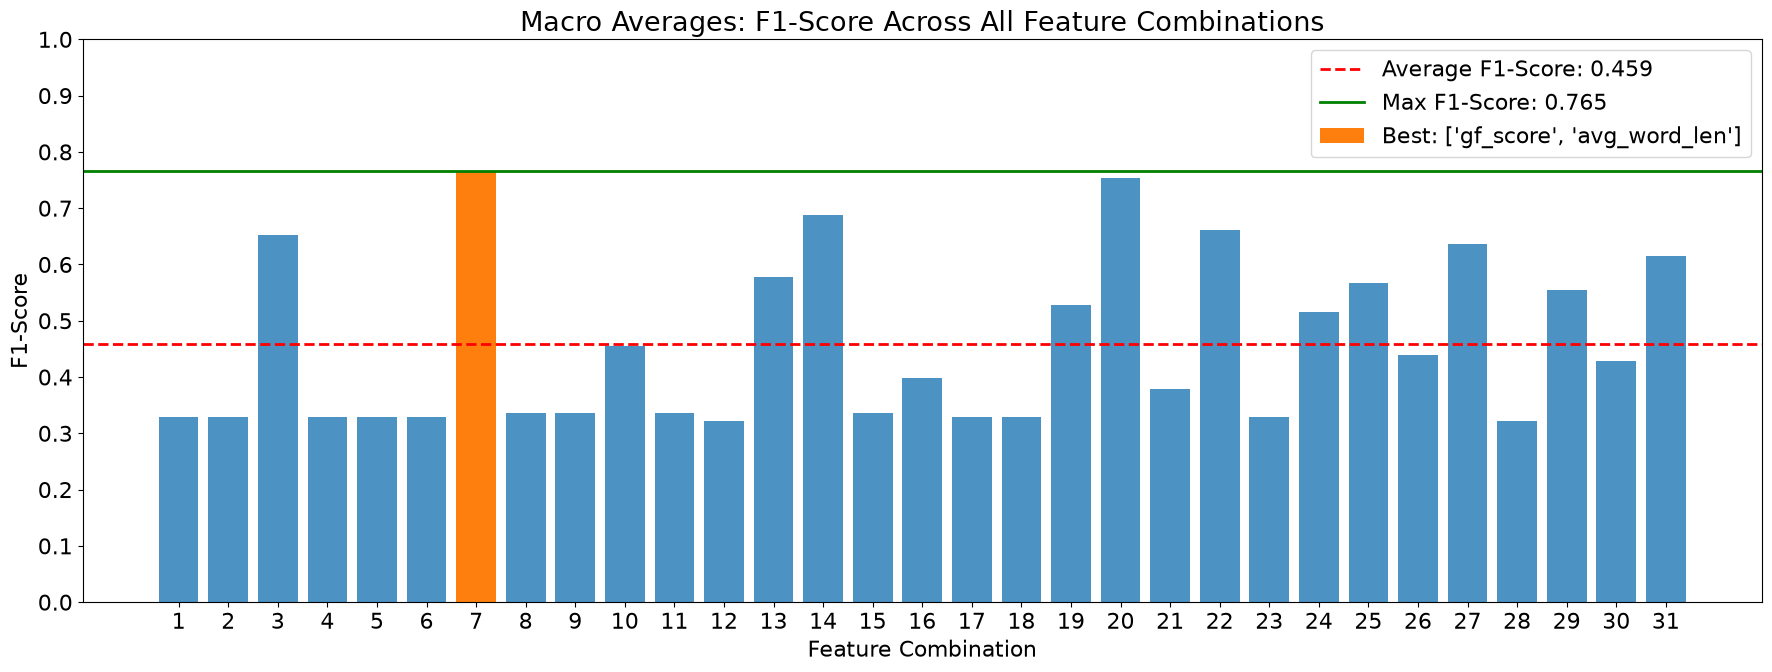

In [91]:
# filtering for only the 'macro avg' rows
mac_avgs = results_df[results_df['class'] == "macro avg"] # Psalter classifier

plot_metric(mac_avgs, "Macro Averages")

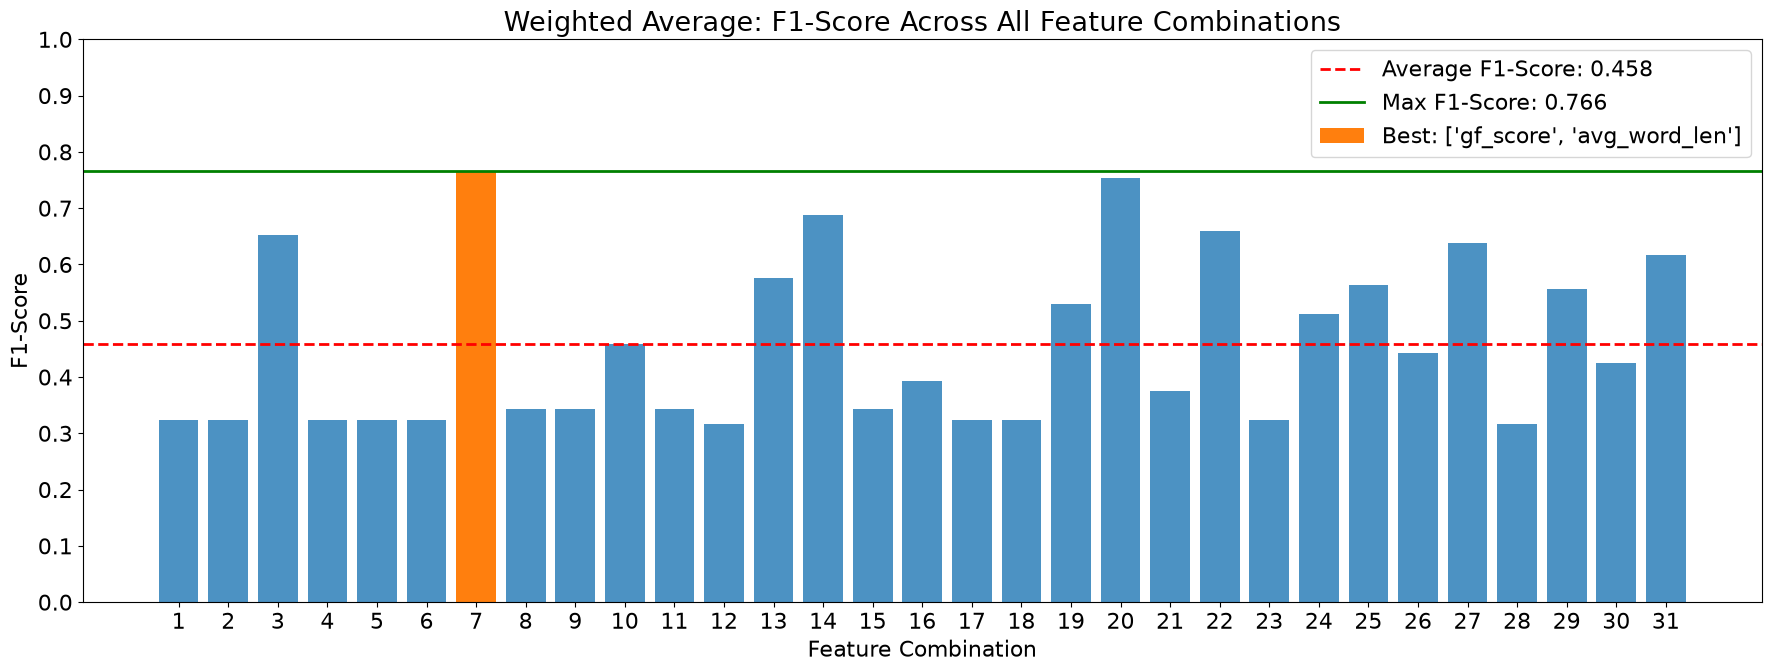

In [92]:
## filtering for only the 'macro avg' rows
w_average = results_df[results_df['class'] == "weighted avg"]# Psalter classifier

plot_metric(w_average, "Weighted Average")

---
# Looking into the specifics of the Perctron model

In [93]:
def perceptron_trial(features):

    # Select features and target
    X = psalms[features]
    y = psalms["text_Psalter"]
    n = len(features)

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # Train model
    perceptron = Perceptron(max_iter=100, eta0=0.1, random_state=42)
    perceptron.fit(X_train, y_train)

    # Predict
    y_pred = perceptron.predict(X_test)

    # Classification metrics
    class_report = classification_report(
        y_test, y_pred, output_dict=True, zero_division=0
    )
    
    accuracy = class_report.pop("accuracy")

    report_df = pd.DataFrame(class_report).T

    report_df = report_df.rename(index={
        "macro avg": "Mac_avg",
        "weighted avg": "weighted_avg"
    })

    report_df.index = report_df.index.map(str)

    report_df = report_df.reindex([
        "0", "1", "Mac_avg", "weighted_avg"
    ])

    # Convert index to a regular column
    report_df = report_df.reset_index(names="class")

    report_df["accuracy"] = accuracy
    report_df["features_used"] = str(features)
    report_df["n_features"] = n

    # Extract coefficients using the exact training feature names
    coef_df = pd.DataFrame(
        perceptron.coef_,
        columns=X_train.columns,
        index=perceptron.classes_ if perceptron.coef_.shape[0] > 1
        else ["decision_function"]
    )

    return report_df, coef_df, perceptron

In [94]:
# full dataFrames
full_results_df = pd.DataFrame()
full_coef_df = pd.DataFrame()

for i in range(len(correlations)):
    features = correlations[:i+1].index.tolist()

    result_df, coef_df, perceptron = perceptron_trial(features)

    #storing the results
    full_results_df = pd.concat([full_results_df, result_df], ignore_index=True)
    full_coef_df = pd.concat([full_coef_df, coef_df], ignore_index=False)

display(full_results_df)
display(full_coef_df)

,class,precision,recall,f1-score,support,accuracy,features_used,n_features
0,0,0.000000,0.000000,0.000000,31.0,0.491803,['gf_score'],1
1,1,0.491803,1.000000,0.659341,30.0,0.491803,['gf_score'],1
2,Mac_avg,0.245902,0.500000,0.329670,61.0,0.491803,['gf_score'],1
3,weighted_avg,0.241870,0.491803,0.324266,61.0,0.491803,['gf_score'],1
4,0,0.000000,0.000000,0.000000,31.0,0.491803,"['gf_score', 'avg_words_sent']",2
...,...,...,...,...,...,...,...,...
151,weighted_avg,0.228943,0.442623,0.301788,61.0,0.442623,"['gf_score', 'avg_words_sent', 'avg_word_len',...",38
152,0,0.000000,0.000000,0.000000,31.0,0.442623,"['gf_score', 'avg_words_sent', 'avg_word_len',...",39
153,1,0.465517,0.900000,0.613636,30.0,0.442623,"['gf_score', 'avg_words_sent', 'avg_word_len',...",39
154,Mac_avg,0.232759,0.450000,0.306818,61.0,0.442623,"['gf_score', 'avg_words_sent', 'avg_word_len',...",39


,gf_score,avg_words_sent,avg_word_len,fk_score,smog_score,bertTopic,subjectivity,compound,neg,num_sentences,...,TTR.2,TTR,MSTTR.2,MSTTR,Word_Count,Word_Count.2,pos,Cohesive_Markers.2,Cohesive_Markers,vader_category_Neutral
decision_function,-0.533171,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,0.940749,-0.688186,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,-3.142233,-1.036542,14.200245,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,-6.894924,-2.534897,19.376925,0.031221,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,-6.396811,-2.354554,17.292530,1.003578,0.916088,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,-6.787380,-1.798641,19.073959,0.801895,1.550922,-3.8,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,-9.034870,-0.509388,24.401947,-1.057946,0.909900,-4.5,3.723125,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,-8.073772,-0.073258,24.569712,-0.898628,1.137098,-5.2,3.419818,0.16134,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,-9.107799,-0.662869,24.642530,-0.667105,0.975519,-5.2,3.575887,-0.57938,0.8500,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,-4.677571,-2.481420,13.389639,-2.136457,1.600855,-4.2,1.739625,0.87106,0.1971,-0.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


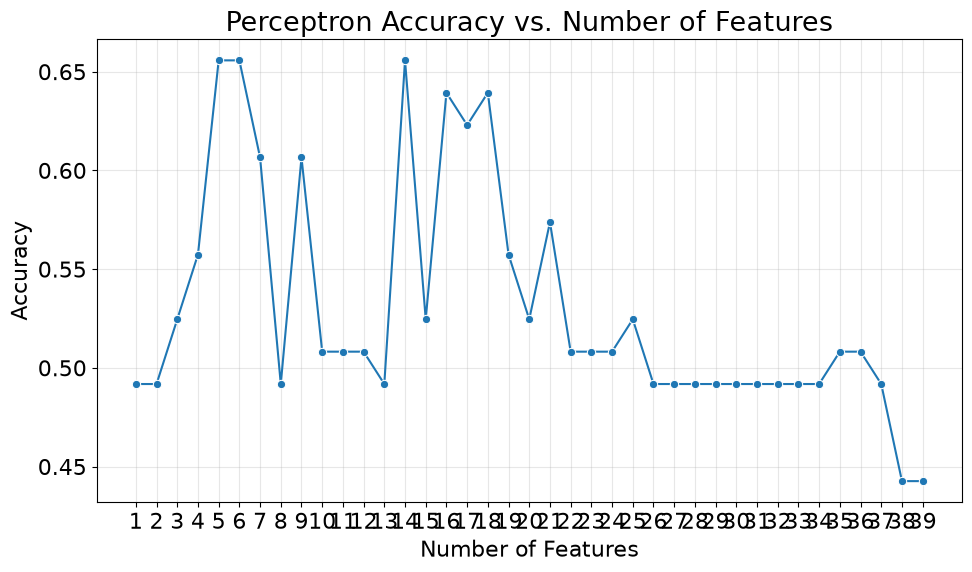

In [95]:
import matplotlib.pyplot as plt
import seaborn as sns

# If all_results has multiple classification-report rows per trial,
# keep one row per trial.
plot_df = full_results_df.drop_duplicates(
    subset=["features_used", "n_features"]
).sort_values("n_features")

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=plot_df,
    x="n_features",
    y="accuracy",
    marker="o"
)

plt.xlabel("Number of Features")
plt.ylabel("Accuracy")
plt.title("Perceptron Accuracy vs. Number of Features")
plt.xticks(sorted(plot_df["n_features"].unique()))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [96]:
# For the coefficients from one trial
weights = coef_df.iloc[0].sort_values()
weights

polysyllable_count        -107.300000
avg_words_sent             -99.718997
Word_Count.2               -72.300000
Word_Count                 -72.300000
gf_score                   -46.538139
fk_score                   -30.998238
smog_score                 -21.984847
bertTopic                  -17.400000
TTR.1                       -0.558497
TTR.3                       -0.558497
TTR.2                       -0.311665
TTR                         -0.311665
vader_category_Negative     -0.300000
MSTTR.3                     -0.172339
MSTTR.1                     -0.172339
neu                         -0.062900
MSTTR                       -0.061968
MSTTR.2                     -0.061968
neg                         -0.060800
vader_category_Neutral       0.000000
avg_syllables_per_word       0.061544
pos                          0.119900
vader_category_Positive      0.300000
emotional_score              0.950064
polarity                     1.144527
compound                     1.383700
subjectivity

In [97]:
# Get coefficients for one trial and sort them
weights = coef_df.iloc[0].sort_values()

# Convert correlations DataFrame to a Series
corr_series = correlations["text_Psalter"]

# Match correlations to coefficients by feature name
weights_df = pd.DataFrame({
    "perceptron_coefficient": weights,
    "correlation": corr_series.reindex(weights.index)
})

display(weights_df)

,perceptron_coefficient,correlation
polysyllable_count,-107.300000,-0.038320
avg_words_sent,-99.718997,-0.323501
Word_Count.2,-72.300000,0.002169
Word_Count,-72.300000,0.002169
gf_score,-46.538139,-0.339740
fk_score,-30.998238,-0.256439
smog_score,-21.984847,-0.211761
bertTopic,-17.400000,-0.085647
TTR.1,-0.558497,-0.033396
TTR.3,-0.558497,-0.033396


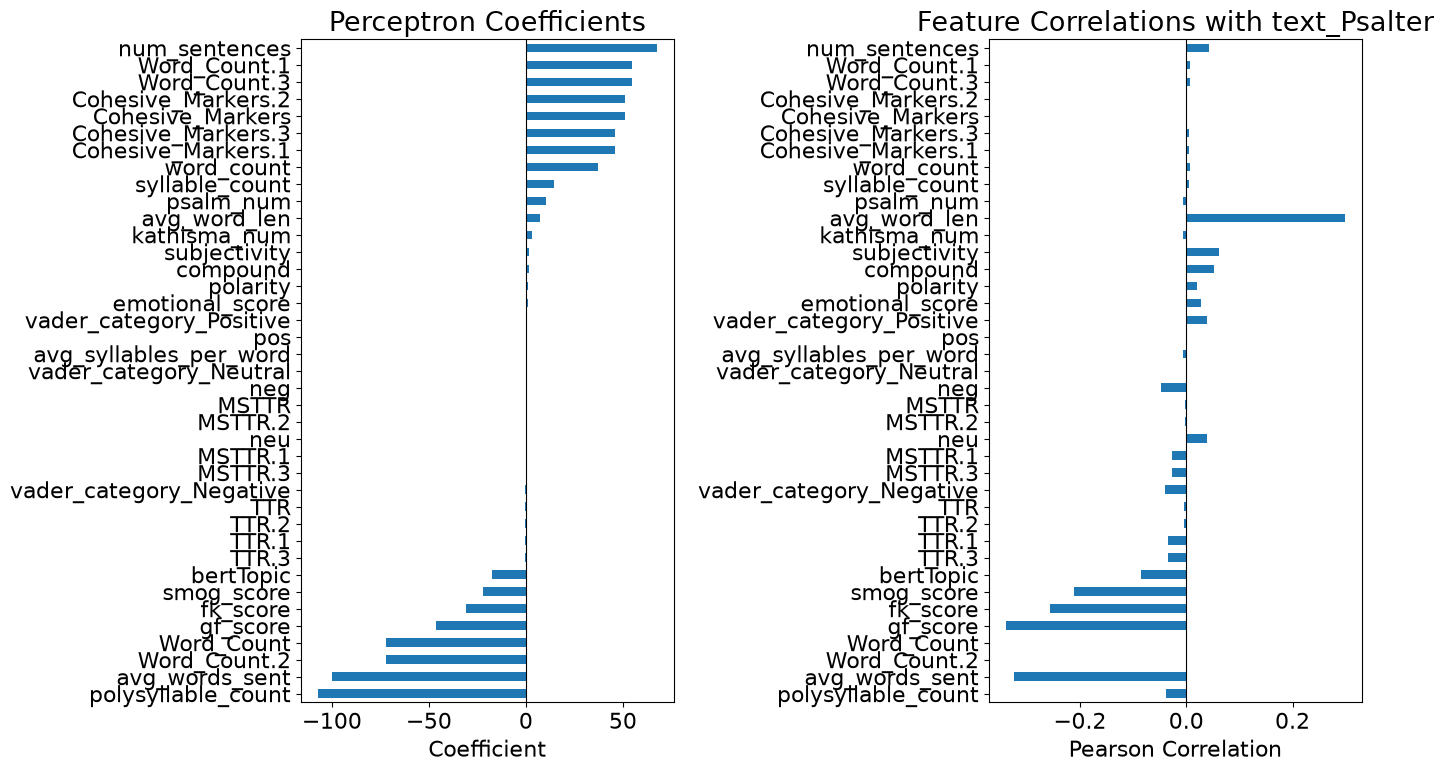

In [98]:
import matplotlib.pyplot as plt

weights_df = weights_df.sort_values("perceptron_coefficient")

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

weights_df["perceptron_coefficient"].plot(
    kind="barh", ax=axes[0], title="Perceptron Coefficients"
)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Coefficient", fontsize=16)

weights_df["correlation"].plot(
    kind="barh", ax=axes[1], title="Feature Correlations with text_Psalter"
)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Pearson Correlation", fontsize=16)

plt.rcParams.update({"font.size": 16})

plt.tight_layout()
plt.show()

## Looking at models with the `Top-N` most contributing features 


In [102]:
print(model.named_steps)

{'simpleimputer': SimpleImputer(), 'standardscaler': StandardScaler(), 'perceptron': Perceptron(max_iter=5000, random_state=42, tol=0.0001)}


In [103]:
import pandas as pd
import numpy as np

perceptron = model.named_steps['perceptron']

contribution_df = pd.DataFrame({
    'feature': X_train.columns,
    'mean_absolute_contribution': np.abs(perceptron.coef_[0])
})

contribution_df = contribution_df.sort_values(
    'mean_absolute_contribution',
    ascending=False
).reset_index(drop=True)

contribution_df

,feature,mean_absolute_contribution
0,vader_category_Neutral,15.330256
1,num_sentences,10.296018
2,avg_word_len,8.769643
3,avg_syllables_per_word,8.229815
4,gf_score,7.865296
5,pos,6.670498
6,compound,6.663500
7,polysyllable_count,6.635065
8,avg_words_sent,4.862485
9,emotional_score,3.535643


In [104]:
from sklearn.linear_model import Perceptron
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Rank features by contribution
ranked_features = contribution_df.sort_values(
    'mean_absolute_contribution', ascending=False
)['feature'].tolist()

# Remove identifiers and metadata
excluded_features = ['psalm_num', 'kathisma_num', 'text_numeric']
ranked_features = [f for f in ranked_features if f not in excluded_features]

results = []

# Split by Psalm number to prevent paired translations leaking
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(
    splitter.split(psalms, psalms['text_Psalter'], groups=psalms['psalm_num'])
)

for n in range(1, len(ranked_features) + 1):

    selected_features = ranked_features[:n]

    X_train = psalms.iloc[train_idx][selected_features]
    X_test = psalms.iloc[test_idx][selected_features]
    y_train = psalms.iloc[train_idx]['text_Psalter']
    y_test = psalms.iloc[test_idx]['text_Psalter']

    # Standardize
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Train model
    model = Perceptron(max_iter=1000, eta0=0.1, random_state=42)
    model.fit(X_train_scaled, y_train)

    # Predict
    y_pred = model.predict(X_test_scaled)

    # Store results
    results.append({
        'Top N Features': n,
        'Features': ', '.join(selected_features),
        'Accuracy': accuracy_score(y_test, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
        'Macro F1': f1_score(y_test, y_pred, average='macro')
    })

results_df = pd.DataFrame(results)

#display(results_df)

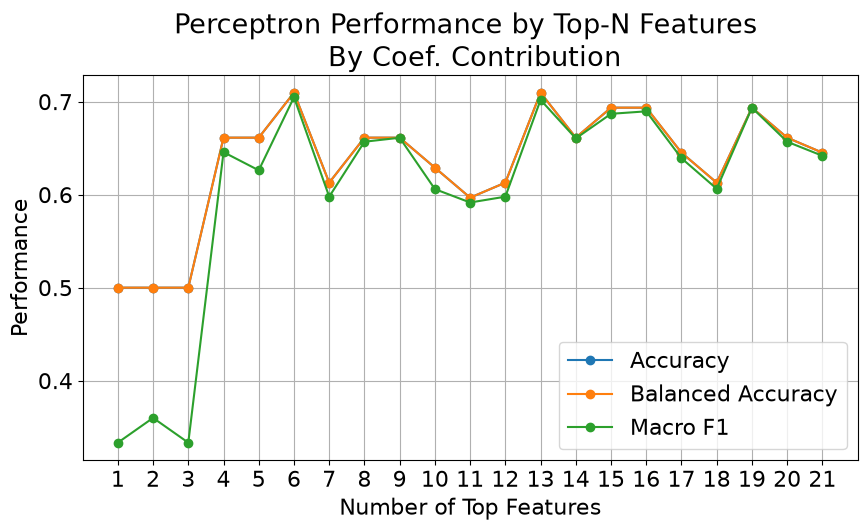

In [105]:
plt.figure(figsize=(10, 5))

plt.plot(results_df['Top N Features'], results_df['Accuracy'], marker='o', label='Accuracy')
plt.plot(results_df['Top N Features'], results_df['Balanced Accuracy'], marker='o', label='Balanced Accuracy')
plt.plot(results_df['Top N Features'], results_df['Macro F1'], marker='o', label='Macro F1')

plt.xlabel('Number of Top Features')
plt.ylabel('Performance')
plt.title('Perceptron Performance by Top-N Features \n By Coef. Contribution')
plt.xticks(range(1, len(ranked_features) + 1))
plt.legend()
plt.grid(True)
plt.show()

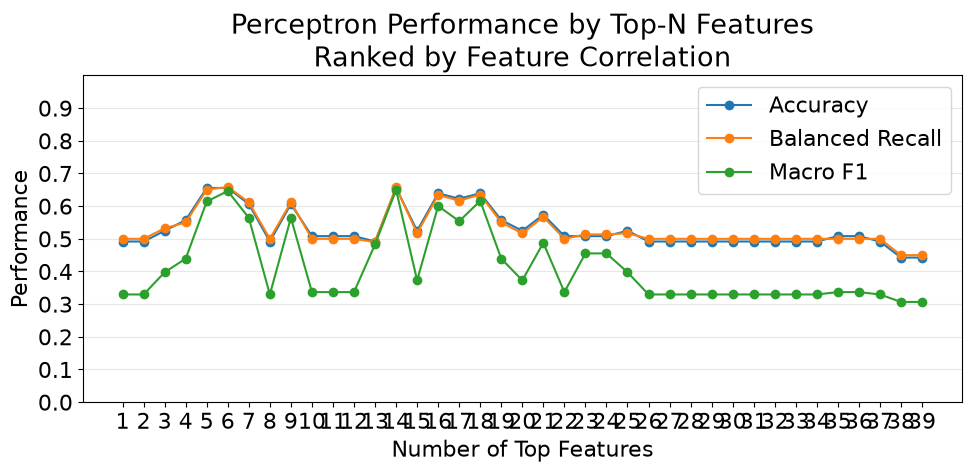

In [106]:
# Select macro-average results
plot_data = n_feature_results[
    n_feature_results['class'] == 'macro avg'
].sort_values('n_features')

plt.figure(figsize=(10, 5))

plt.plot(plot_data['n_features'], plot_data['accuracy'],
         marker='o', label='Accuracy')

plt.plot(plot_data['n_features'], plot_data['recall'],
         marker='o', label='Balanced Recall')

plt.plot(plot_data['n_features'], plot_data['f1-score'],
         marker='o', label='Macro F1')

plt.xlabel('Number of Top Features')
plt.ylabel('Performance')
plt.title('Perceptron Performance by Top-N Features\nRanked by Feature Correlation')

plt.xticks(range(1, len(plot_data) + 1))
plt.ylim(0, 1)


plt.yticks(np.arange(0, 1, 0.1))

plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Looking for Bias

,Actual,Predicted
Bible,31,0.0
Psalter,30,61.0


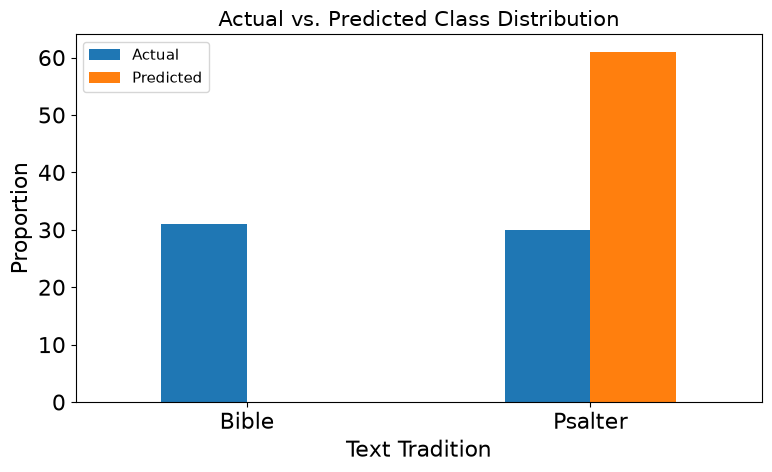

In [107]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Select your features and target
X = psalms[features]
y = psalms["text_Psalter"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = Perceptron(max_iter=100, eta0=0.1, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Compare actual and predicted class distributions
bias_df = pd.DataFrame({
    "Actual": y_test.value_counts(normalize=False),
    "Predicted": pd.Series(y_pred).value_counts(normalize=False)
}).fillna(0)

bias_df.index = bias_df.index.map({0: "Bible", 1: "Psalter"})
display(bias_df)

bias_df.plot(kind="bar", figsize=(8, 5))
plt.title("Actual vs. Predicted Class Distribution", fontsize=15)
plt.ylabel("Proportion")
plt.xlabel("Text Tradition")
plt.xticks(rotation=0)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

## Standardizing the Features 



In [108]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron

model = make_pipeline(
    StandardScaler(),
    Perceptron(
        max_iter=1000,
        eta0=0.1,
        random_state=42
    )
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('perceptron', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](39,)","['gf_score','avg_words_sent','avg_word_len',...,'Cohesive_Markers.2', 'Cohesive_Markers','vader_category_Neutral']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,39
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [109]:
coefficients = model.named_steps['perceptron'].coef_[0]

coef_df = pd.DataFrame({
    'feature': X_train.columns,
    'coefficient': coefficients
})

coef_df['abs_coefficient'] = coef_df['coefficient'].abs()

coef_df.sort_values(
    'abs_coefficient',
    ascending=False
)

,feature,coefficient,abs_coefficient
38,vader_category_Neutral,1.552431,1.552431
2,avg_word_len,1.517315,1.517315
13,polysyllable_count,-1.344376,1.344376
0,gf_score,-1.022862,1.022862
9,num_sentences,0.990454,0.990454
7,compound,0.848319,0.848319
35,pos,-0.766767,0.766767
14,TTR.3,-0.743426,0.743426
15,TTR.1,-0.743426,0.743426
8,neg,0.662169,0.662169


In [110]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

In [111]:
# Calculate feature contributions
contributions = pd.DataFrame(
    X_train_scaled * perceptron.coef_[0],
    columns=X_train.columns
)

# Average absolute contribution
contribution_df = pd.DataFrame({
    "feature": contributions.columns,
    "mean_absolute_contribution": contributions.abs().mean().values,
    "mean_signed_contribution": contributions.mean().values
})

contribution_df = contribution_df.sort_values(
    "mean_absolute_contribution",
    ascending=False
)

display(contribution_df)

ValueError: operands could not be broadcast together with shapes (240,39) (22,) 

---

# Modeling after Feature Categories

This helps answer a more meaningful question:

**Which features actually contribute the most to the model's predictions across the dataset?**

We are now going to train three different models with the following targeted feature categories: 
- sentiment features - *10 features*
- linguistic features - *10 features*
- readabilty features - *3 features*
- translationese features - **
- all features - *20 features*

In [112]:
sentiment_features = [
    'pos', 'neg', 'neu', 'compound', 'polarity', 'subjectivity',
    'emotional_score', 'vader_category_Negative',
    'vader_category_Neutral', 'vader_category_Positive'
]

linguistic_features = [
    'word_count', 'syllable_count', 'polysyllable_count',
    'avg_word_len', 'avg_syllables_per_word', 'num_sentences',
    'avg_words_sent', 'fk_score', 'gf_score', 'smog_score'
]

readability_features = ['fk_score', 'gf_score', 'smog_score']

combined_features = sentiment_features + linguistic_features

In [ ]:
# Training all 4 models again 
model_feature_sets = {
    "Sentiment Model": sentiment_features,
    "Linguistic Model": linguistic_features,
    "Readabilty Model": readabilty_features,
    "Combined Model": combined_features
}

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.linear_model import Perceptron
from sklearn.preprocessing import StandardScaler

# Data splitting
from sklearn.model_selection import train_test_split

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score
)

In [ ]:
results = []

for model_name, feature_set in model_feature_sets.items():

    print(f"\n{'='*50}")
    print(f"Training: {model_name}")
    print(f"{'='*50}")

    # Select features
    X = psalms[feature_set]
    y = psalms['text_Psalter']

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    # Standardize features
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Train Perceptron
    perceptron = Perceptron(
        max_iter=1000,
        eta0=0.1,
        random_state=42
    )

    perceptron.fit(X_train_scaled, y_train)

    # Predictions
    y_pred = perceptron.predict(X_test_scaled)

    # Decision scores
    decision_scores = perceptron.decision_function(X_test_scaled)

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    # Classification metrics
    accuracy = accuracy_score(y_test, y_pred)
    balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro')

    # Prediction distributions
    actual_0 = (y_test == 0).mean()
    actual_1 = (y_test == 1).mean()

    predicted_0 = (y_pred == 0).mean()
    predicted_1 = (y_pred == 1).mean()

    # Store results
    results.append({
        "Model": model_name,
        "Features": len(feature_set),

        # Overall performance
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced_accuracy,
        "Macro F1": macro_f1,

        # Class-specific metrics
        "Bible Precision": precision_score(
            y_test, y_pred, pos_label=0, zero_division=0
        ),
        "Bible Recall": recall_score(
            y_test, y_pred, pos_label=0, zero_division=0
        ),
        "Psalter Precision": precision_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Psalter Recall": recall_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),

        # Confusion matrix
        "True Bible": tn,
        "False Psalter": fp,
        "False Bible": fn,
        "True Psalter": tp,

        # Prediction distribution
        "Actual Bible %": actual_0,
        "Actual Psalter %": actual_1,
        "Predicted Bible %": predicted_0,
        "Predicted Psalter %": predicted_1,

        # Model diagnostics
        "Intercept": perceptron.intercept_[0],
        "Mean Decision Score": np.mean(decision_scores),
        "Min Decision Score": np.min(decision_scores),
        "Max Decision Score": np.max(decision_scores),
        "Mean Absolute Decision Score": np.mean(
            np.abs(decision_scores)
        )
    })

    print("Accuracy:", accuracy)
    print("Balanced Accuracy:", balanced_accuracy)
    print("Macro F1:", macro_f1)

    print("\nActual class distribution:")
    print(y_test.value_counts(normalize=True).sort_index())

    print("\nPredicted class distribution:")
    print(pd.Series(y_pred).value_counts(normalize=True).sort_index())

    print("\nIntercept:", perceptron.intercept_[0])

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))


# Convert results into DataFrame
results_df = pd.DataFrame(results)

# Sort by Macro F1
results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

- The combined model does the best overall. 
    - this shows that there is no one specific category of features that is best to determine if the Psalm is either from the `Psalter` or from `The Book of Psalms`. 

### Overall Preformance
 | Model | Accuracy | Balanced Accuracy | Macro F1 |
|:---|---:|---:|---:|
| Combined Model | **50.82%** | **50.75%** | **0.5070** |
| Sentiment Model | 47.54% | 47.53% | 0.4753 |
| Linguistic Model | 45.90% | 45.75% | 0.4537 |
| Readability Model | 47.54% | 48.28% | 0.3476 |

### Class Specific

| Model | Bible Precision | Bible Recall | Psalter Precision | Psalter Recall |
|:---|---:|---:|---:|---:|
| Combined Model | 51.52% | 50.00% | 54.84% | 50.00% |
| Sentiment Model | 48.39% | 46.67% | 46.67% | 46.67% |
| Linguistic Model | 47.22% | 36.67% | 54.84% | 54.84% |
| Readability Model | 33.33% | 3.23% | 48.28% | 93.33% |


### Actual vs. Predicted

| Model | Actual Bible | Actual Psalter | Predicted Bible | Predicted Psalter |
|:---|---:|---:|---:|---:|
| Combined Model | 50.82% | 49.18% | 54.10% | 45.90% |
| Sentiment Model | 50.82% | 49.18% | 50.82% | 49.18% |
| Linguistic Model | 50.82% | 49.18% | 59.02% | 40.98% |
| Readability Model | 50.82% | 49.18% | 4.92% | 95.08% |


### Decision Scores
| Model | Intercept | Mean Decision Score | Min Decision Score | Max Decision Score | Mean Absolute Decision Score |
|:---|---:|---:|---:|---:|---:|
| Combined Model | 0.2 | 0.4830 | -3.5648 | 24.1158 | 1.8380 |
| Sentiment Model | 0.0 | 0.1650 | -1.8671 | 24.3755 | 1.0162 |
| Linguistic Model | -0.1 | -0.0759 | -1.9516 | 1.4890 | 0.4205 |
| Readability Model | 0.1 | 0.0926 | -0.0458 | 0.2367 | 0.0963 |

#### Key: 
**Decision Score	Interpretation**
- Negative - Favors Bible (class 0)
- Positive - Favors Psalter (class 1)
- Near zero - Close to the classification boundary

In [ ]:
'''Ranked Coefficients by Absolute Magnitude'''

coef_df = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": perceptron.coef_[0]
})

coef_df["abs_coefficient"] = coef_df["coefficient"].abs()

coef_df["direction"] = np.where(
    coef_df["coefficient"] > 0,
    "Psalter",
    "Bible"
)

coef_df = coef_df.sort_values(
    by="abs_coefficient",
    ascending=False
)

display(coef_df)

## Invesitgating Colinearity

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = X.corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0
)

plt.title('Feature Correlation Matrix')
plt.show()

---
## Looking at Other Models

In [ ]:

import pandas as pd

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    train_test_split
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Your five best features
target_features = [
    "subjectivity",
    "compound",
    "vader_category_Positive",
    "neu",
    "emotional_score"
]

# Predictor variables and target
X = psalms[target_features]
y = psalms["text_Psalter"]

# Stratified train-test split for final evaluation
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Define the three models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    ),

    "Linear SVM": make_pipeline(
        StandardScaler(),
        LinearSVC(
            C=1.0,
            max_iter=5000,
            random_state=42
        )
    ),

    "MLP Neural Network": make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(8,),
            activation="relu",
            solver="adam",
            alpha=0.01,
            max_iter=2000,
            early_stopping=True,
            random_state=42
        )
    )
}

# Five-fold stratified cross-validation on training data
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy"
}

results = []
trained_models = {}

for name, model in models.items():

    # Cross-validation using training data only
    cv_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    # Fit on the entire training set
    model.fit(X_train, y_train)
    trained_models[name] = model

    # Evaluate on the held-out test set
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "CV Accuracy": cv_scores["test_accuracy"].mean(),
        "CV Accuracy SD": cv_scores["test_accuracy"].std(),
        "CV F1": cv_scores["test_f1"].mean(),
        "CV Balanced Accuracy":
            cv_scores["test_balanced_accuracy"].mean(),
        "Test Accuracy": accuracy_score(y_test, y_pred)
    })

# Display results, best cross-validation accuracy first
results_df = pd.DataFrame(results).sort_values(
    "CV Accuracy",
    ascending=False
)

print(results_df.to_string(index=False))


In [ ]:

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Bible", "Psalter"],
        zero_division=0
    ))
